# Figure 1b. Trans-eQTL coherence and size of gene programs

**Left:** for each variant-program pair where the program is active (Bonferroni minP), the coherence fraction is the share of the program's genes with a nominal trans-eQTL association to the variant. Bars show the distribution of coherence fractions in five bins, for Hotspot and WGCNA programs in MetaBrain, eQTLGen and ROSMAP. The number in parentheses is the number of variants with at least one active program. Red asterisks mark a one-sided Wilcoxon test (Hotspot > WGCNA) with P < 0.05.

**Right:** number of genes per program, Hotspot vs WGCNA, in GTEx brain cortex, GTEx whole blood and ROSMAP.

Input: `data/Figure_1b_coherence.rds`, `data/Figure_1b_program_size.rds`.

In [1]:
library(ggplot2)
library(patchwork)
library(scales)

coherence <- readRDS("data/Figure_1b_coherence.rds")
program_size <- readRDS("data/Figure_1b_program_size.rds")
str(coherence$bins)
coherence$tests

'data.frame':	30 obs. of  7 variables:
 $ dataset      : Factor w/ 3 levels "MetaBrain","eQTLGen",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ method       : Factor w/ 2 levels "WGCNA","Hotspot": 1 1 1 1 1 2 2 2 2 2 ...
 $ coherence_bin: Factor w/ 5 levels "<1%","1-5%","5-10%",..: 1 2 3 4 5 1 2 3 4 5 ...
 $ n_pairs      : int  54 24 25 1 0 31 261 166 27 0 ...
 $ n_variants   : int  69 69 69 69 69 205 205 205 205 205 ...
 $ total_pairs  : int  104 104 104 104 104 485 485 485 485 485 ...
 $ proportion   : num  0.51923 0.23077 0.24038 0.00962 0 ...


n_pairs_hotspot,n_pairs_wgcna,median_fraction_hotspot,median_fraction_wgcna,wilcox_p_greater,cliffs_delta,dataset
<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
485,104,0.04000000,0.009009009,1.664009e-11,0.4139175,MetaBrain
4445,1178,0.03846154,0.014185111,4.064925e-147,0.4881953,Brain (ROSMAP)
9438,2565,0.03703704,0.014925373,1.079964e-304,0.4794274,eQTLGen


## Coherence-fraction bins

In [2]:
bin_colors <- c("<1%" = "#E8E8E8", "1-5%" = "#C8D9E8", "5-10%" = "#85ACC8",
                "10-20%" = "#E0A85A", ">20%" = "#B5524A")

bins <- coherence$bins
bins$y_label <- paste0(bins$method, "\n(", format(bins$n_variants, big.mark = ",", trim = TRUE), ")")
bins$y_label <- factor(bins$y_label, levels = unique(bins$y_label[order(bins$dataset, bins$method)]))
bins$label <- ifelse(bins$proportion >= 0.07, percent(bins$proportion, accuracy = 1), "")

tests <- coherence$tests
tests$star <- ifelse(tests$wilcox_p_greater < 0.05, "*", "")
tests$y_low <- sapply(tests$dataset, function(d) as.character(unique(bins$y_label[bins$dataset == d & bins$method == "WGCNA"])))
tests$y_high <- sapply(tests$dataset, function(d) as.character(unique(bins$y_label[bins$dataset == d & bins$method == "Hotspot"])))

p_left <- ggplot(bins, aes(x = proportion, y = y_label, fill = coherence_bin)) +
  geom_col(width = 0.68, colour = "white", linewidth = 0.3, position = position_stack(reverse = TRUE)) +
  geom_text(aes(label = label), position = position_stack(vjust = 0.5, reverse = TRUE), size = 4) +
  geom_segment(data = tests, aes(x = 1.02, xend = 1.02, y = y_low, yend = y_high), inherit.aes = FALSE, linewidth = 0.35) +
  geom_segment(data = tests, aes(x = 0.99, xend = 1.02, y = y_low, yend = y_low), inherit.aes = FALSE, linewidth = 0.35) +
  geom_segment(data = tests, aes(x = 0.99, xend = 1.02, y = y_high, yend = y_high), inherit.aes = FALSE, linewidth = 0.35) +
  geom_text(data = tests, aes(x = 1.07, y = y_high, label = star), inherit.aes = FALSE,
            size = 7, fontface = "bold", colour = "#B2182B", vjust = 1.2) +
  facet_wrap(~ dataset, ncol = 1, scales = "free_y") +
  scale_fill_manual(values = bin_colors, name = NULL) +
  scale_x_continuous(labels = percent_format(accuracy = 1), breaks = seq(0, 1, 0.25),
                     limits = c(0, 1.12), expand = expansion(mult = c(0, 0.02))) +
  labs(x = expression("Variant-program " * italic("trans") * "-eQTL coherence"), y = NULL) +
  theme_classic(base_size = 16) +
  theme(strip.background = element_blank(), strip.text = element_text(size = 18),
        panel.grid.major.x = element_line(colour = "grey90", linewidth = 0.25),
        legend.position = "bottom")

## Number of genes per program

In [3]:
method_colors <- c("Hotspot" = "#2166AC", "WGCNA" = "#E6A817")

size_ns <- aggregate(program_size ~ dataset, data = program_size, FUN = max)
size_ns$y <- size_ns$program_size * 1.02

p_right <- ggplot(program_size, aes(x = method, y = program_size, colour = method, fill = method)) +
  geom_violin(width = 0.75, linewidth = 0.85, alpha = 0.18, trim = TRUE, scale = "width") +
  geom_jitter(width = 0.12, alpha = 0.3, size = 2, shape = 16) +
  geom_text(data = size_ns, aes(x = 1.5, y = y, label = "ns"), inherit.aes = FALSE,
            size = 5, colour = "grey35", hjust = -0.15) +
  facet_wrap(~ dataset, ncol = 1, scales = "free_x") +
  scale_colour_manual(values = method_colors, guide = "none") +
  scale_fill_manual(values = method_colors, guide = "none") +
  scale_x_discrete(limits = c("WGCNA", "Hotspot")) +
  scale_y_continuous(expand = expansion(mult = c(0.02, 0.10)), breaks = breaks_pretty(n = 4)) +
  labs(x = NULL, y = "# Genes in Programs") +
  coord_flip(clip = "off") +
  theme_classic(base_size = 16) +
  theme(strip.background = element_blank(), strip.text = element_text(size = 18),
        panel.grid.major.x = element_line(colour = "grey90", linetype = "dashed"))

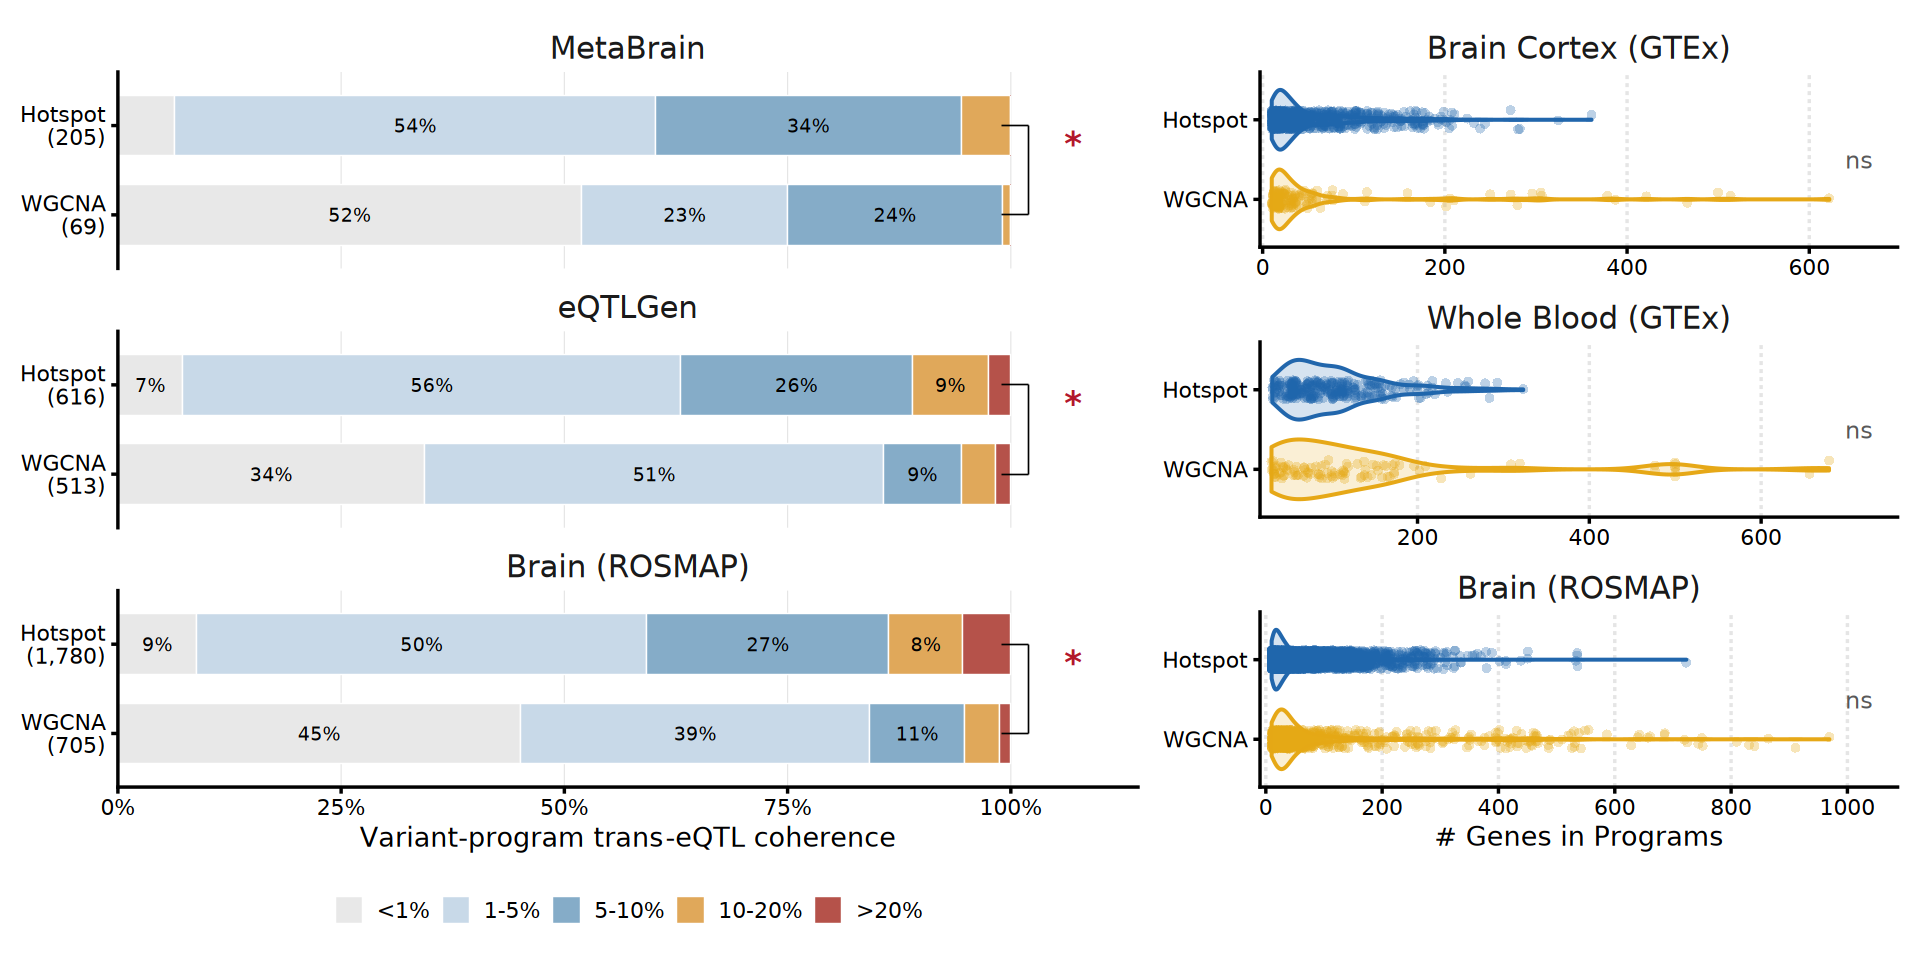

In [4]:
options(repr.plot.width = 16, repr.plot.height = 8)
p_left + p_right + plot_layout(widths = c(1.6, 1))